# COCO-MLT with ResNet-50 (ImageNet, input 448): the RTN skeleton

This notebook only says **which dataset and which encoder**. Everything
else (the RTN components, MulSupCon as host and baseline, the split,
seeds, measurements and decision rule) comes from `rtn_skeleton.py`, so
every experiment runs exactly the same skeleton. 

**Encoder.** ResNet-50 trained on ImageNet labels (input 448, chosen in round 7),
a different architecture from the two ViTs.

## Step 0: dataset, encoder and settings

In [1]:
import importlib
import os
import sys

# This notebook can sit in the project folder or in a folder inside it. The
# project folder is the one with coco_mlt/ and the round 6 files; every path
# below is relative to it.
HERE = os.path.abspath("")
PROJECT = next((p for p in (HERE, os.path.dirname(HERE))
                if os.path.isdir(os.path.join(p, "coco_mlt"))
                and os.path.exists(os.path.join(p, "relation_contrastive_runs.py"))), None)
if PROJECT is None:
    raise SystemExit("Put this notebook in the project folder (the one with coco_mlt/ and "
                     "relation_contrastive_runs.py) or in a folder inside it.")
copies = {os.path.join(p, "rtn_skeleton.py") for p in (HERE, PROJECT)
          if os.path.exists(os.path.join(p, "rtn_skeleton.py"))}
if not copies:
    raise SystemExit("rtn_skeleton.py not found next to this notebook or in the project folder.")
if len(copies) > 1 and len({open(c, "rb").read() for c in copies}) > 1:
    raise SystemExit("There are two different copies of rtn_skeleton.py; keep only one.")
for p in (HERE, PROJECT):
    if p not in sys.path:
        sys.path.insert(0, p)
os.chdir(PROJECT)

import rtn_skeleton as sk
importlib.reload(sk)
print(f"Project folder: {PROJECT}\nSkeleton: {sk.__file__} (version {sk.SKELETON_VERSION})")

DATASET = dict(name="COCO-MLT", folder="coco_mlt",
               definitions=dict(file="coco_mlt/relations/coco_to_synset.json",
                                url=sk.COCO_WORDNET_URL))
ENCODER = dict(key="resnet50", label="ResNet-50 (ImageNet, input 448)",
               features="coco_mlt/encoders/resnet50_448/features",
               old_runs="coco_mlt/round7/relation_contrastive_resnet50/runs",
               extract="python coco_mlt_encoder_features.py --encoder resnet50 --input 448")
QUICK_TEST = False      # True = tiny run to test the code only
WORKERS = "auto"        # trainings at the same time ("auto" or a number)
RETRAIN = False         # True reruns this encoder's runs, ignoring saved ones

exp = sk.Experiment(DATASET, ENCODER, quick_test=QUICK_TEST, workers=WORKERS, retrain=RETRAIN)

Project folder: c:\Users\Admin\Documents\MSc-Project---RTN
Skeleton: c:\Users\Admin\Documents\MSc-Project---RTN\RTN\rtn_skeleton.py (version 1)
COCO-MLT, ResNet-50 (ImageNet, input 448): skeleton version 1; results in c:\Users\Admin\Documents\MSc-Project---RTN\coco_mlt\rtn_skeleton\resnet50


## Step 1: the skeleton, and a self-test of the host code (MulSupCon)

In [2]:
exp.setup()

numpy 2.5.4, pandas 3.1.0, torch 2.11.0+cu130
Device: NVIDIA GeForce RTX 4070 Laptop GPU (8.0 GB)


,component,fixed choice
0,skeleton version,1
1,relation source,GloVe 6B 300-d vectors of the class name + its...
2,related classes,top 5% most similar names
3,relation values,"1 related + seen together, 0.5 related + never..."
4,where RTN acts,"MulSupCon's negatives, weight w = 1 + 1 x R"
5,host and baseline,MulSupCon's official pipeline (round 6 code 20...
6,split and seeds,80% / 20% training / dev split (seed 0); seeds...
7,measurements,test AP per class group; related-class gap on ...
8,decision rule,"RTN works if, against MulSupCon, tail AP impro..."


,check,passed
0,MulSupCon loss and gradients equal the officia...,True
1,"with alpha 0, RTN is exactly MulSupCon",True
2,RTN: fast loss equals the row-by-row definition,True
3,"queue: batch keys only until full, then batch ...",True


## Step 2: relation source and related classes (GloVe + WordNet, no CLIP)

In [3]:
exp.relations()

GloVe words not found (ignored): {'baseball glove': ['handwear'], 'donut': ['friedcake']}
Related classes (top 5% most similar names) of the tail classes and of names with several meanings:


,class,cohort,WordNet meaning,related classes
0,airplane,tail,an aircraft that has a fixed wing and is power...,"car, motorcycle, boat, traffic light"
1,train,tail,public or private transport provided by a line...,"car, bus, truck, traffic light"
2,fire hydrant,tail,an upright hydrant for drawing water to use in...,"car, traffic light, remote, sink"
3,stop sign,tail,a traffic sign to notify drivers that they mus...,"bus, train, traffic light, clock"
4,parking meter,tail,a coin-operated timer located next to a parkin...,"bicycle, car, bus, traffic light"
5,bird,tail,animal characterized by feathers and wings,"dog, cow, bear, giraffe"
6,horse,tail,a common horse,"cat, dog, cow, elephant"
7,sheep,tail,woolly usually horned ruminant mammal related ...,"dog, cow, elephant, bear"
8,cow,tail,cattle that are reared for their meat,"bird, dog, horse, sheep"
9,elephant,tail,a common elephant,"dog, horse, sheep, giraffe"


## Step 3: data for the host code, and checks that it runs exactly the skeleton

In [4]:
exp.prepare()

,check,passed
0,the host code's class similarity is the skelet...,True
1,the host code's relation types equal the skele...,True
2,the host code's negative weights are w = 1 + R,True
3,the labels match the class list,True


Training images: 1516 for training, 393 for the dev set; test images: 5000. Skeleton fingerprint: ac9d3bf7088a. Relation pairs (training part):


,cohort,classes,related_seen,related_never,informative
0,head,22,82,6,159
1,medium,33,80,52,149
2,tail,25,21,79,41


## Step 4: train MulSupCon and RTN, 3 seeds each (resumable)

In [5]:
exp.train()

Reused the saved MulSupCon runs of seeds 42, 43, 44 from coco_mlt/round7/relation_contrastive_resnet50/runs (MulSupCon uses no relation types).
3 of 6 runs are saved; 3 to do.
16 CPU threads, 1.5 GB memory free, 8.0 GB GPU memory -> up to 1 training(s) at once (limited by free memory: close other programs and other notebooks' kernels, then rerun this cell, to allow more)
Estimated time: up to about 84 min (1.4 h), 1 at a time. Fine-tuning usually stops early, so it is often shorter.
    epoch   1/150: running loss 5.5535 (11 s)
    epoch  25/150: running loss 5.2112 (275 s)
    epoch  50/150: running loss 5.1930 (546 s)
    epoch  75/150: running loss 5.1805 (828 s)
    epoch 100/150: running loss 5.1830 (1108 s)
    epoch 125/150: running loss 5.1793 (1387 s)
    epoch 150/150: running loss 5.1808 (1671 s)
  [1/3] RTN, seed 42: dev mAP 58.16; fine-tuning best epoch 27 of 47 (28.0 min); about 56 min left in this phase
    epoch   1/150: running loss 5.5557 (12 s)
    epoch  25/150: run

,variant,seed,dev mAP,best epoch,converged,from an earlier round
0,MulSupCon,42,57.74,28,True,True
1,MulSupCon,43,56.28,27,True,True
2,MulSupCon,44,58.34,28,True,True
3,RTN,42,58.16,27,True,False
4,RTN,43,58.17,29,True,False
5,RTN,44,58.62,28,True,False


## Step 5: test mAP per class group (mean +/- sd over the 3 seeds)

In [6]:
exp.results()

,encoder,variant,all mAP,head mAP,medium mAP,tail mAP
0,"ResNet-50 (ImageNet, input 448)",MulSupCon (no relation types),52.91 +/- 0.05,51.31 +/- 0.60,57.98 +/- 0.75,47.62 +/- 1.07
1,"ResNet-50 (ImageNet, input 448)",RTN skeleton: MulSupCon + relation-typed negat...,52.64 +/- 0.32,51.36 +/- 0.25,57.52 +/- 0.06,47.32 +/- 1.20


## Step 6: related-class confusion by relation type

For each tail class, how much more often test images of related classes
(and informative companions) outrank its true positives than images of
unrelated classes never seen with it (AUC points; Control 1 matches the
number of objects, Control 2 centres each image's scores). Lower is better.

In [7]:
exp.confusion()

Computed in 1 s. Average gap per relation type (AUC points, minus the baseline group; lower is better):


,variant,"related, seen together, C1","related, seen together, C2","related, never together, C1","related, never together, C2","informative companion, C1","informative companion, C2","generic companion, C1","generic companion, C2"
0,MulSupCon,13.92,20.98,4.13,7.81,5.58,10.49,1.73,0.58
1,RTN,13.25,20.12,3.77,7.52,5.24,10.61,1.74,0.58


Change in the gap, RTN vs MulSupCon (95% interval; below 0 = less confusion):


,type,Control 1,Control 2
0,"related, seen together","-0.67 [-1.74, +0.30]","-0.86 [-3.32, +0.96]"
1,"related, never together","-0.36 [-0.85, +0.09]","-0.29 [-1.43, +0.85]"
2,informative companion,"-0.34 [-0.84, +0.09]","+0.12 [-0.60, +0.69]"
3,generic companion,"+0.00 [-0.17, +0.14]","+0.00 [-0.37, +0.32]"


## Step 7: verdict (decision rule fixed before running)

In [8]:
exp.verdict()

COCO-MLT, ResNet-50 (ImageNet, input 448): RTN vs MulSupCon NOT SHOWN (tail AP -0.30 [-1.39, +0.77], higher in 2 of 3 seeds; related-class gap C1 -0.31 [-0.81, +0.14], C2 -0.32 [-1.62, +0.89]; head AP +0.06; overall AP -0.27 [-0.69, +0.16])


,dataset,encoder,MulSupCon all / tail mAP,RTN all / tail mAP,tail AP change,higher tail mAP (seeds),head AP change,all AP change,"gap change, C1","gap change, C2",verdict
0,COCO-MLT,"ResNet-50 (ImageNet, input 448)",52.91 / 47.62,52.64 / 47.32,"-0.30 [-1.39, +0.77]",2/3,"+0.06 [-0.44, +0.55]","-0.27 [-0.69, +0.16]","-0.31 [-0.81, +0.14]","-0.32 [-1.62, +0.89]",NOT SHOWN


## Step 8: figure and saved results

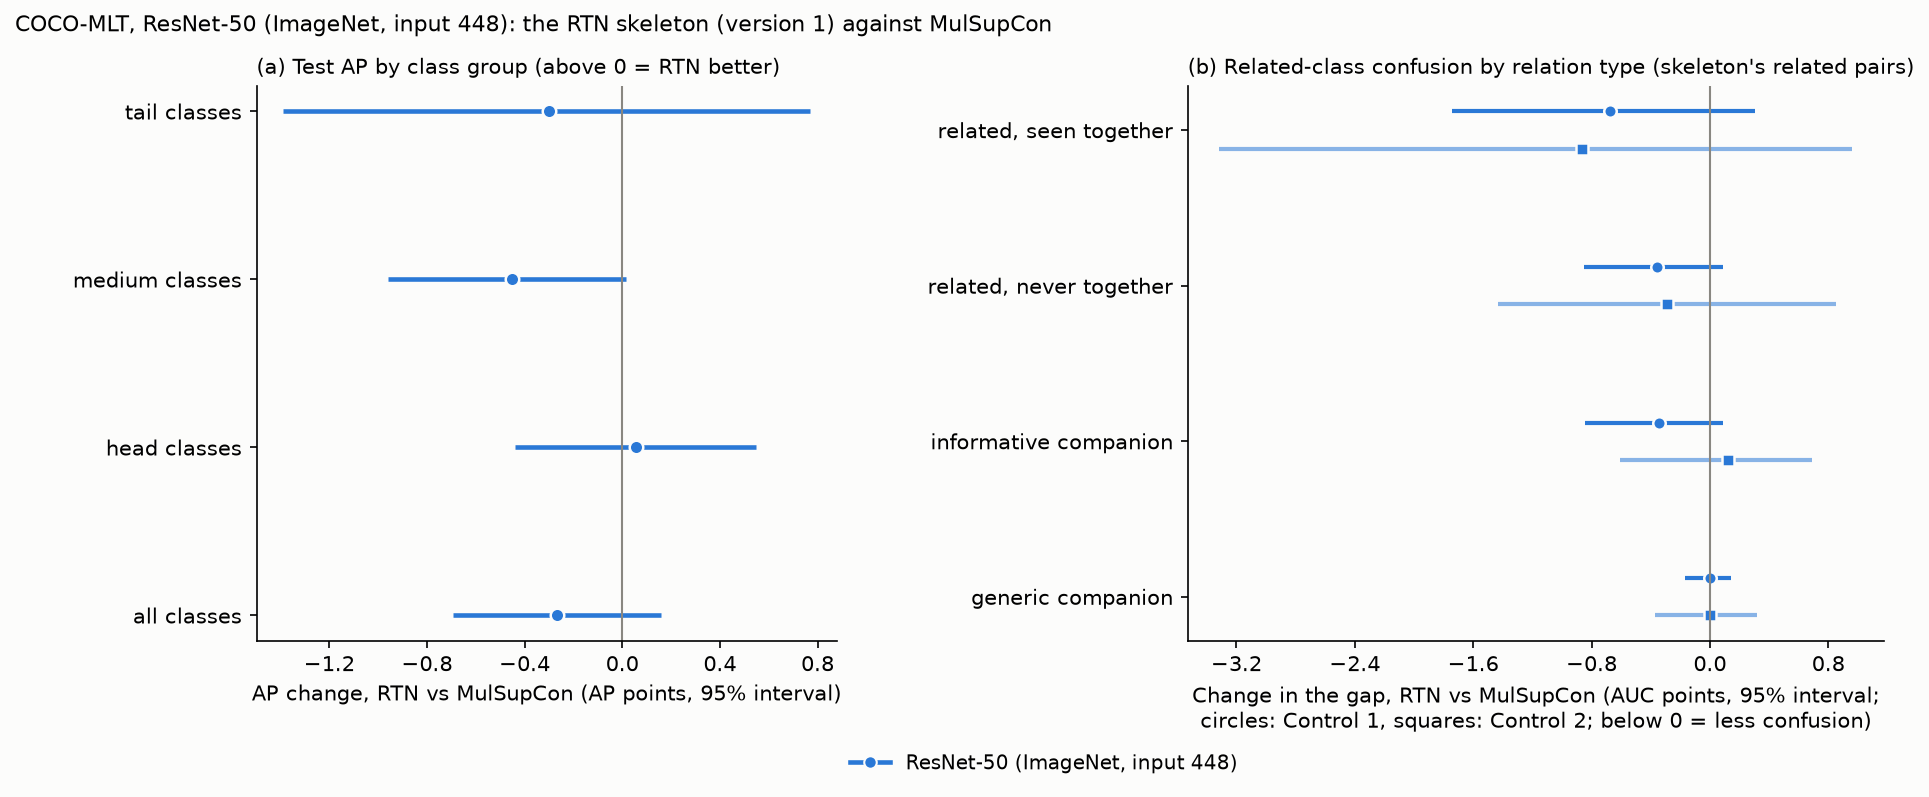

Saved coco_mlt\rtn_skeleton\resnet50\figure.png
Saved the tables, result.json and summary.txt to c:\Users\Admin\Documents\MSc-Project---RTN\coco_mlt\rtn_skeleton\resnet50


In [9]:
exp.figure()
exp.save()

## How to read the results

- Step 7 is the result for this encoder. Under the rule fixed in advance,
  PARTLY can sit alongside a tail AP drop, so always read the tail AP
  change next to the verdict.
- For context: with the earlier relation types (from CLIP's class-name
  text), RTN raised tail AP by +0.82 on ResNet-50 (round 7), higher in 3
  of 3 seeds. Matching that without CLIP is the first bar.